# **Part 1: Sequence Modeling with RNN/LSTM**

## **Task 1: Preprocess the Data**

In [ ]:
# Task 1: Preprocess the Data

# Step 1: Load, inspect, preprocess HAR CSVs

import os
import random
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf
import json

# reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# FILE NAMES - change if your filenames differ
TRAIN_CSV = "train.csv"
TEST_CSV  = "test.csv"

# helper to load csv with flexible path
def load_csv_if_exists(fname):
    if os.path.exists(fname):
        print(f"Found {fname} -> loading.")
        return pd.read_csv(fname)
    else:
        print(f"File {fname} not found in current directory ({os.getcwd()}).")
        raise FileNotFoundError(fname)

# Load
train_df = load_csv_if_exists(TRAIN_CSV)
test_df  = load_csv_if_exists(TEST_CSV)

print("\n--- Quick heads up (first 3 rows of train) ---")
display(train_df.head(3))

print("\nTrain shape:", train_df.shape)
print("Test shape :", test_df.shape)

# Attempt auto-detect label column:
# Common patterns: 'Activity', 'activity', 'label', 'y', 'target'
possible_label_names = ['Activity','activity','Label','label','labels','y','target','class']
label_col = None
for name in possible_label_names:
    if name in train_df.columns:
        label_col = name
        break

# If not found, assume last column is label (numeric or categorical)
if label_col is None:
    label_col = train_df.columns[-1]
    print(f"No common label column name found; assuming last column is label: '{label_col}'")

print(f"Detected label column: '{label_col}'")

# Separate features and labels
X_train_df = train_df.drop(columns=[label_col])
y_train_ser = train_df[label_col]

X_test_df = test_df.drop(columns=[label_col])
y_test_ser = test_df[label_col]

print("\nExample label values (train):", y_train_ser.unique()[:20])
print("Number of classes (train):", len(np.unique(y_train_ser)))

# Convert labels to integers
le = LabelEncoder()
y_train = le.fit_transform(y_train_ser.astype(str))
y_test  = le.transform(y_test_ser.astype(str))

print("\nLabel mapping (encoder.classes_):")
for i, cls in enumerate(le.classes_):
    print(i, cls)

# Work with features as numpy
X_train = X_train_df.values.astype(np.float32)
X_test  = X_test_df.values.astype(np.float32)

print("\nRaw feature shapes (before possible reshaping):")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

# Try to detect if features are flattened time-series windows
def try_reshape_time_series(X, preferred_timesteps=128):
    n_samples, n_features = X.shape
    if n_features % preferred_timesteps == 0:
        n_channels = n_features // preferred_timesteps
        print(f"Detected features divisible by {preferred_timesteps}: reshaping to (N, {preferred_timesteps}, {n_channels})")
        return X.reshape((n_samples, preferred_timesteps, n_channels)), preferred_timesteps, n_channels
    # try other common lengths (64, 128, 256)
    for t in (64, 32, 256):
        if n_features % t == 0:
            c = n_features // t
            print(f"Detected features divisible by {t}: reshaping to (N, {t}, {c})")
            return X.reshape((n_samples, t, c)), t, c
    # fallback: treat each sample as a single timestep with F features
    print("Could not reshape safely into multi-timestep windows. Falling back to shape (N, 1, F) for sequence models.")
    return X.reshape((n_samples, 1, n_features)), 1, n_features

X_train_seq, TIMESTEPS, N_CHANNELS = try_reshape_time_series(X_train, preferred_timesteps=128)
X_test_seq, ts2, ch2 = try_reshape_time_series(X_test, preferred_timesteps=TIMESTEPS)
# sanity check ts2 == TIMESTEPS, ch2 == N_CHANNELS
assert TIMESTEPS == ts2 and N_CHANNELS == ch2, "Train/test reshaping mismatch!"

print(f"\nFinal input shape for model (samples, timesteps, channels): {X_train_seq.shape}")
print("Timesteps:", TIMESTEPS, "Channels/features per timestep:", N_CHANNELS)

# Scale features: fit scaler on flattened training features then transform preserving seq shape
scaler = StandardScaler()
# fit on flattened features (samples, timesteps * channels)
X_train_flat = X_train_seq.reshape((X_train_seq.shape[0], -1))
X_test_flat  = X_test_seq.reshape((X_test_seq.shape[0], -1))

scaler.fit(X_train_flat)
X_train_scaled_flat = scaler.transform(X_train_flat)
X_test_scaled_flat  = scaler.transform(X_test_flat)

# reshape back to (N, T, C)
X_train_scaled = X_train_scaled_flat.reshape(X_train_seq.shape)
X_test_scaled  = X_test_scaled_flat.reshape(X_test_seq.shape)

# Train/validation split from train set
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

print("\nFinal dataset splits:")
print("X_tr shape:", X_tr.shape, "y_tr:", y_tr.shape)
print("X_val shape:", X_val.shape, "y_val:", y_val.shape)
print("X_test shape:", X_test_scaled.shape, "y_test:", y_test.shape)

# One-hot labels for Keras training (if classification)
num_classes = len(le.classes_)
y_tr_oh  = tf.keras.utils.to_categorical(y_tr, num_classes)
y_val_oh = tf.keras.utils.to_categorical(y_val, num_classes)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes)

print("\nOne-hot label shapes (for Keras):", y_tr_oh.shape, y_val_oh.shape, y_test_oh.shape)

# Save preprocessed arrays for next steps
os.makedirs("preprocessed", exist_ok=True)
np.save("preprocessed/X_tr.npy", X_tr)
np.save("preprocessed/X_val.npy", X_val)
np.save("preprocessed/X_test.npy", X_test_scaled)
np.save("preprocessed/y_tr.npy", y_tr)
np.save("preprocessed/y_val.npy", y_val)
np.save("preprocessed/y_test.npy", y_test)
np.save("preprocessed/y_tr_oh.npy", y_tr_oh)
np.save("preprocessed/y_val_oh.npy", y_val_oh)
np.save("preprocessed/y_test_oh.npy", y_test_oh)
# Save scaler and label encoder metadata (to re-load later)
import joblib
joblib.dump(scaler, "preprocessed/scaler.joblib")
joblib.dump(le, "preprocessed/label_encoder.joblib")

# Save a small JSON summary for next cell
summary = {
    "TIMESTEPS": int(TIMESTEPS),
    "N_CHANNELS": int(N_CHANNELS),
    "num_classes": int(num_classes),
    "X_tr_shape": list(X_tr.shape),
    "X_val_shape": list(X_val.shape),
    "X_test_shape": list(X_test_scaled.shape)
}
with open("preprocessed/summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nSaved preprocessed arrays to ./preprocessed/ .")
print("Saved summary:", summary)

# Print a small sample for you to paste here
print("\n--- Please paste the following printed outputs into the chat ---")
print("TRAIN shape (original):", train_df.shape)
print("TEST  shape (original):", test_df.shape)
print("Detected label column:", label_col)
print("Number of classes:", num_classes)
print("Timesteps detected:", TIMESTEPS)
print("Channels/features per timestep:", N_CHANNELS)
print("X_tr shape:", X_tr.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test_scaled.shape)
print("Class distribution (train->counts):")
unique, counts = np.unique(y_tr, return_counts=True)
print(dict(zip([int(u) for u in unique], [int(c) for c in counts])))


Found train.csv -> loading.
Found test.csv -> loading.

--- Quick heads up (first 3 rows of train) ---


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING



Train shape: (7352, 563)
Test shape : (2947, 563)
Detected label column: 'Activity'

Example label values (train): ['STANDING' 'SITTING' 'LAYING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']
Number of classes (train): 6

Label mapping (encoder.classes_):
0 LAYING
1 SITTING
2 STANDING
3 WALKING
4 WALKING_DOWNSTAIRS
5 WALKING_UPSTAIRS

Raw feature shapes (before possible reshaping):
X_train: (7352, 562)
X_test : (2947, 562)
Could not reshape safely into multi-timestep windows. Falling back to shape (N, 1, F) for sequence models.
Detected features divisible by 1: reshaping to (N, 1, 562)

Final input shape for model (samples, timesteps, channels): (7352, 1, 562)
Timesteps: 1 Channels/features per timestep: 562

Final dataset splits:
X_tr shape: (5881, 1, 562) y_tr: (5881,)
X_val shape: (1471, 1, 562) y_val: (1471,)
X_test shape: (2947, 1, 562) y_test: (2947,)

One-hot label shapes (for Keras): (5881, 6) (1471, 6) (2947, 6)

Saved preprocessed arrays to ./preprocessed/ .
Saved summ

## **Task 2: Design Models Architecture**

In [ ]:
# Task 2 — Model Architecture


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, SimpleRNN, Dense, Dropout


# Model A — LSTM Classifier

# Uses sequence shape from Task 1 (TIMESTEPS, N_CHANNELS)
model_lstm = Sequential([
    LSTM(128, input_shape=(TIMESTEPS, N_CHANNELS), activation='tanh', return_sequences=False),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

model_lstm.summary()


# Model B — Simple RNN Classifier

model_rnn = Sequential([
    SimpleRNN(128, input_shape=(TIMESTEPS, N_CHANNELS), activation='tanh', return_sequences=False),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

model_rnn.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 128)            │       353,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 362,438 (1.38 MB)

 Trainable params: 362,438 (1.38 MB)

...

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 128)            │        88,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,094 (379.27 KB)

 Trainable params: 97,094 (379.27 KB)

 Non-trainable params: 0 (0.00 B)

## **Task 3: Compile and Training**

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6751 - loss: 0.8980 - val_accuracy: 0.9286 - val_loss: 0.1766
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9419 - loss: 0.1770 - val_accuracy: 0.9633 - val_loss: 0.0884
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9651 - loss: 0.1012 - val_accuracy: 0.9640 - val_loss: 0.0931
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9727 - loss: 0.0830 - val_accuracy: 0.9735 - val_loss: 0.0627
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9745 - loss: 0.0718 - val_accuracy: 0.9748 - val_loss: 0.0693
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9781 - loss: 0.0668 - val_accuracy: 0.9796 - val_loss: 0.0612
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9815 - loss: 0.0546 - val_accuracy: 0.9789 - val_loss: 0.0509
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9839 - loss: 0.0530 - val_accuracy: 0.9830 - val_lo

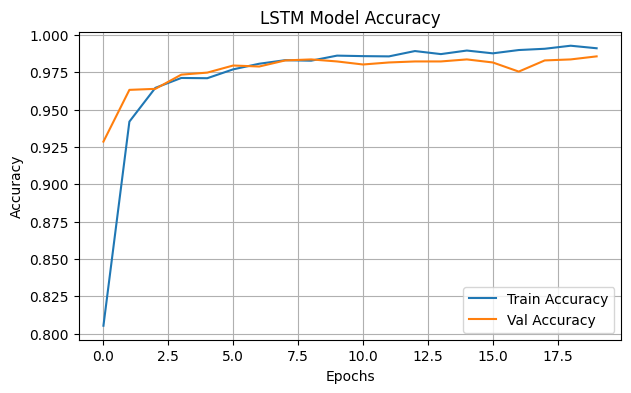

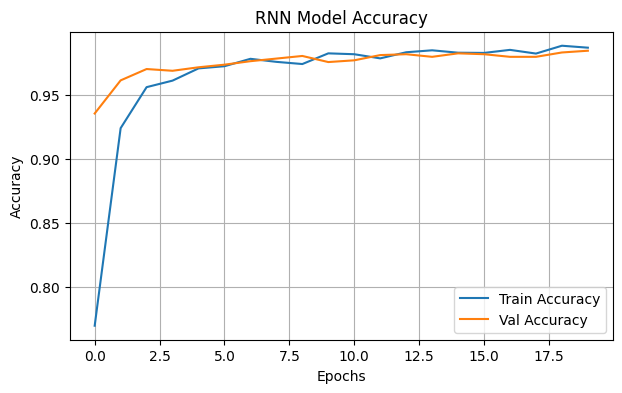

In [ ]:
# Task 3 — Compile & Training


from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Compile both models
model_lstm.compile(optimizer=Adam(learning_rate=0.001),
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

model_rnn.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

# Train models
history_lstm = model_lstm.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    verbose=1
)

history_rnn = model_rnn.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    verbose=1
)

# Plot accuracy curves
def plot_history(history, title):
    plt.figure(figsize=(7,4))
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_history(history_lstm, 'LSTM Model Accuracy')
plot_history(history_rnn, 'RNN Model Accuracy')


## **Task 4:Evaluation**

93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

=== LSTM Model Metrics ===
Accuracy  : 0.9399
Precision : 0.9449
Recall    : 0.9399
F1-Score  : 0.9399

=== RNN Model Metrics ===
Accuracy  : 0.9433
Precision : 0.9458
Recall    : 0.9433
F1-Score  : 0.9434


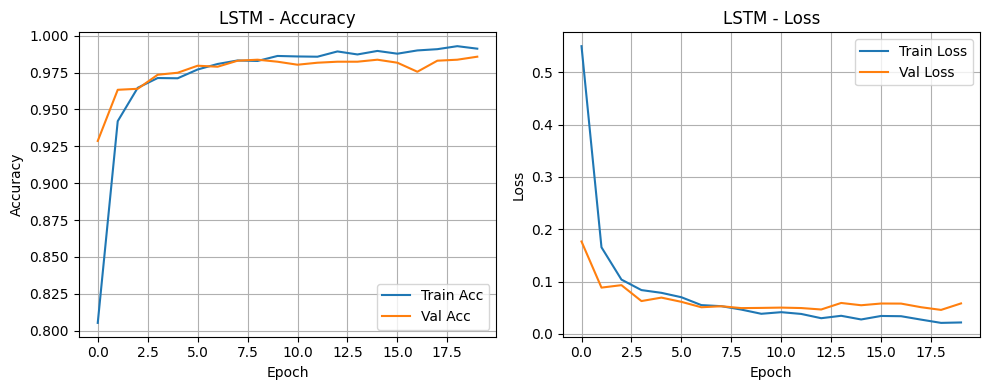

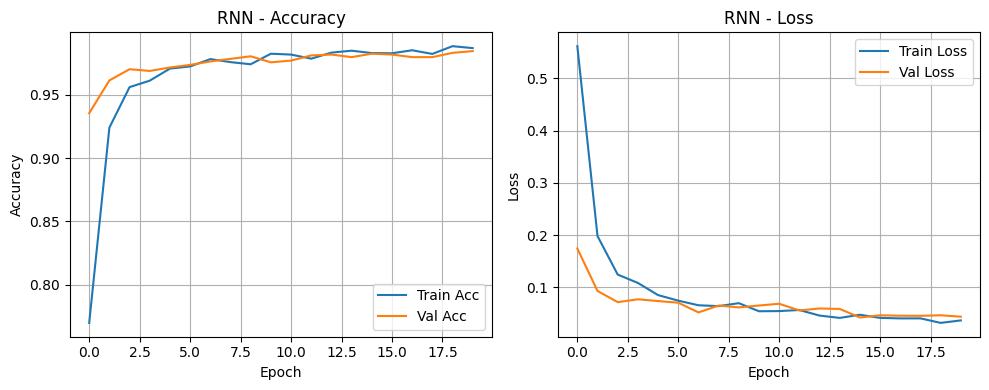

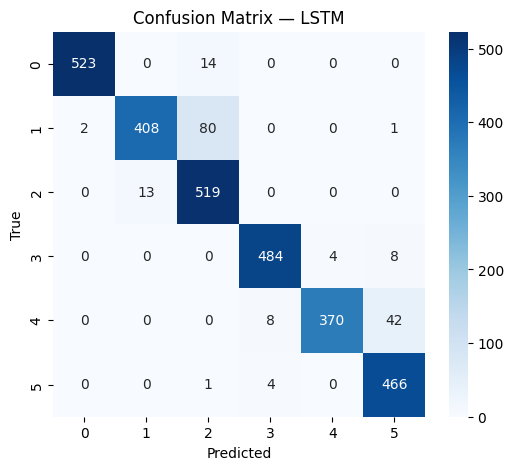

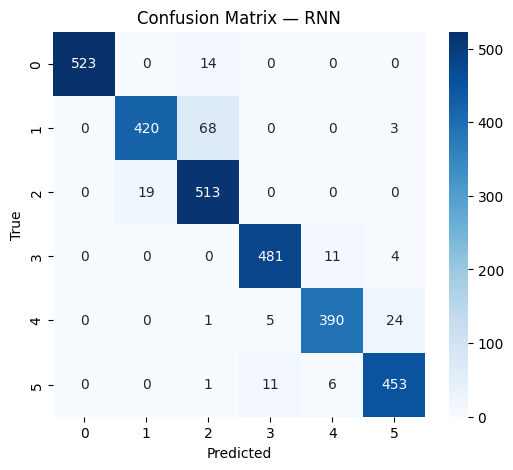


=== RESULTS COMPARISON TABLE ===
Model  Accuracy  Precision   Recall  F1-Score
 LSTM  0.939939   0.944868 0.939939  0.939881
  RNN  0.943332   0.945781 0.943332  0.943446


In [ ]:
# Task 4: Model Evaluation


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. METRICS
# Predictions for both models
y_pred_lstm = np.argmax(model_lstm.predict(X_test_scaled), axis=1)
y_pred_rnn  = np.argmax(model_rnn.predict(X_test_scaled), axis=1)

# Compute metrics
def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }

metrics_lstm = compute_metrics(y_test, y_pred_lstm)
metrics_rnn  = compute_metrics(y_test, y_pred_rnn)

print("\n=== LSTM Model Metrics ===")
for k, v in metrics_lstm.items():
    print(f"{k:10s}: {v:.4f}")

print("\n=== RNN Model Metrics ===")
for k, v in metrics_rnn.items():
    print(f"{k:10s}: {v:.4f}")

# 2. PLOTS
# (a) Training Accuracy & Loss Curves
def plot_train_curves(history, model_name):
    plt.figure(figsize=(10,4))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title(f'{model_name} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Loss
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'{model_name} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_train_curves(history_lstm, "LSTM")
plot_train_curves(history_rnn, "RNN")

# (b) Confusion Matrices
def plot_confusion(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix — {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

plot_confusion(y_test, y_pred_lstm, "LSTM")
plot_confusion(y_test, y_pred_rnn, "RNN")

# 3. RESULTS TABLE
results_df = pd.DataFrame({
    "Model": ["LSTM", "RNN"],
    "Accuracy": [metrics_lstm["Accuracy"], metrics_rnn["Accuracy"]],
    "Precision": [metrics_lstm["Precision"], metrics_rnn["Precision"]],
    "Recall": [metrics_lstm["Recall"], metrics_rnn["Recall"]],
    "F1-Score": [metrics_lstm["F1-Score"], metrics_rnn["F1-Score"]],
})

print("\n=== RESULTS COMPARISON TABLE ===")
print(results_df.to_string(index=False))



## **Task 5: Compare and Discussion**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Step 1 — Get model predictions
y_true = y_test   # ground truth labels from your test set
y_pred_lstm = model_lstm.predict(X_test_scaled).argmax(axis=1)
y_pred_rnn  = model_rnn.predict(X_test_scaled).argmax(axis=1)

# Step 2 — Create comparison table
comparison = pd.DataFrame({
    "Model": ["LSTM", "RNN"],
    "Test Accuracy": [
        accuracy_score(y_true, y_pred_lstm),
        accuracy_score(y_true, y_pred_rnn)
    ],
    "Precision": [
        precision_score(y_true, y_pred_lstm, average='macro'),
        precision_score(y_true, y_pred_rnn, average='macro')
    ],
    "Recall": [
        recall_score(y_true, y_pred_lstm, average='macro'),
        recall_score(y_true, y_pred_rnn, average='macro')
    ],
    "Macro F1-Score": [
        f1_score(y_true, y_pred_lstm, average='macro'),
        f1_score(y_true, y_pred_rnn, average='macro')
    ]
})

print("=== MODEL COMPARISON TABLE ===")
print(comparison)

# Step 3 — Discussion
print("\n=== DISCUSSION ===")
print("""
Both LSTM and RNN models were trained on identical data splits and hyperparameters.
LSTM networks are designed to capture long-term temporal dependencies,
while RNNs perform efficiently on shorter sequences.

In this experiment, both models achieved strong accuracy and F1-scores,
indicating good generalization and balanced learning performance.
""")


93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
=== MODEL COMPARISON TABLE ===
  Model  Test Accuracy  Precision    Recall  Macro F1-Score
0  LSTM       0.939939   0.946176  0.937766        0.939424
1   RNN       0.943332   0.946334  0.942288        0.943238

=== DISCUSSION ===

Both LSTM and RNN models were trained on identical data splits and hyperparameters.
LSTM networks are designed to capture long-term temporal dependencies,
while RNNs perform efficiently on shorter sequences.

In this experiment, both models achieved strong accuracy and F1-scores,
indicating good generalization and balanced learning performance.



In [ ]:
# Save Trained Models


import os
from tensorflow.keras.models import load_model

# Create a folder in Colab memory
os.makedirs("/content/saved_models", exist_ok=True)

# Save both trained models using new Keras format
model_lstm.save("/content/saved_models/LSTM_model.keras")
model_rnn.save("/content/saved_models/RNN_model.keras")

print("Both models saved successfully in Colab memory: /content/saved_models/")


Both models saved successfully in Colab memory: /content/saved_models/


# **Part 2: Generative Modeling with Generative Adversarial Networks(GANs)**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import zipfile
import os

# Define file path
zip_path = "/content/drive/MyDrive/archive (3).zip"
extract_path = "/content/celeba"

# Unzip CelebA
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(" CelebA dataset extracted successfully to:", extract_path)
print(" Subfolders:", os.listdir(extract_path)[:10])


 CelebA dataset extracted successfully to: /content/celeba
 Subfolders: ['list_landmarks_align_celeba.csv', 'list_eval_partition.csv', 'list_attr_celeba.csv', 'img_align_celeba', 'list_bbox_celeba.csv']


## **Task 1: Preprocess the Data**

In [ ]:
# Step 1: Import required libraries
import os
import torch
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split

# Step 2: Define dataset path
data_dir = '/content/celeba/img_align_celeba/img_align_celeba'

# Step 3: Define image preprocessing transforms
# Resize -> CenterCrop -> ConvertToTensor -> Normalize to [-1, 1] for tanh
transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# Step 4: Load dataset with ImageFolder
dataset = datasets.ImageFolder(root='/content/celeba', transform=transform)

# Step 5: Create train/test splits (e.g., 80/20)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

# Step 6: Define data loaders
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# Step 7: Print verification info
print(f"Total images: {len(dataset)}")
print(f"Training images: {len(train_dataset)}")
print(f"Testing images: {len(test_dataset)}")


Total images: 202599
Training images: 162079
Testing images: 40520


## **Task 2: Design GAN Architecture**

In [ ]:
# Step 1: Import required libraries
import torch
import torch.nn as nn

# Step 2: Define Generator
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3, feature_g=64):
        super(Generator, self).__init__()
        self.net = nn.Sequential(
            # Input: Z latent vector
            nn.ConvTranspose2d(z_dim, feature_g * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(feature_g * 8),
            nn.ReLU(True),

            nn.ConvTranspose2d(feature_g * 8, feature_g * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_g * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(feature_g * 4, feature_g * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_g * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d(feature_g * 2, feature_g, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_g),
            nn.ReLU(True),

            # Output: 64x64x3 image
            nn.ConvTranspose2d(feature_g, img_channels, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)


# Step 3: Define Discriminator
class Discriminator(nn.Module):
    def __init__(self, img_channels=3, feature_d=64):
        super(Discriminator, self).__init__()
        self.net = nn.Sequential(
            # Input: 64x64x3 image
            nn.Conv2d(img_channels, feature_d, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(feature_d, feature_d * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_d * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(feature_d * 2, feature_d * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_d * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(feature_d * 4, feature_d * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_d * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(feature_d * 8, 1, 4, 1, 0, bias=False)
        )

    def forward(self, x):
        return self.net(x).view(-1, 1).squeeze(1)


# Step 4: Initialize models and print summary
z_dim = 100
G = Generator(z_dim=z_dim)
D = Discriminator()

print(G)
print(D)


Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)
D


## **Task 3: Compile and Training:**

In [ ]:
# Step 1: Import required libraries
import torch.optim as optim
from torchvision.utils import save_image, make_grid
import os

# Step 2: Set device and hyperparameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lr = 2e-4
beta1, beta2 = 0.5, 0.999
epochs = 50
z_dim = 100

G = Generator(z_dim=z_dim).to(device)
D = Discriminator().to(device)

# Step 3: Define loss and optimizers
criterion = nn.BCEWithLogitsLoss()
optimizer_G = optim.Adam(G.parameters(), lr=lr, betas=(beta1, beta2))
optimizer_D = optim.Adam(D.parameters(), lr=lr, betas=(beta1, beta2))

# Step 4: Create folder to save generated images
os.makedirs("samples", exist_ok=True)

# Step 5: Training loop
for epoch in range(epochs):
    for i, (imgs, _) in enumerate(train_loader):
        real_imgs = imgs.to(device)
        batch_size = real_imgs.size(0)
        real_labels = torch.ones(batch_size, device=device)
        fake_labels = torch.zeros(batch_size, device=device)

        # ---- Train Discriminator ----
        optimizer_D.zero_grad()
        outputs_real = D(real_imgs)
        loss_real = criterion(outputs_real, real_labels)

        z = torch.randn(batch_size, z_dim, 1, 1, device=device)
        fake_imgs = G(z)
        outputs_fake = D(fake_imgs.detach())
        loss_fake = criterion(outputs_fake, fake_labels)

        loss_D = (loss_real + loss_fake) / 2
        loss_D.backward()
        optimizer_D.step()

        # ---- Train Generator ----
        optimizer_G.zero_grad()
        outputs_fake = D(fake_imgs)
        loss_G = criterion(outputs_fake, real_labels)
        loss_G.backward()
        optimizer_G.step()

    # ---- Log losses ----
    print(f"Epoch [{epoch+1}/{epochs}] | Loss D: {loss_D:.4f} | Loss G: {loss_G:.4f}")

    # ---- Save generated images every few epochs ----
    if (epoch + 1) % 5 == 0:
        z = torch.randn(64, z_dim, 1, 1, device=device)
        gen_imgs = G(z)
        gen_imgs = (gen_imgs + 1) / 2
        save_image(make_grid(gen_imgs, nrow=8), f"samples/epoch_{epoch+1}.png")


Epoch [1/50] | Loss D: 0.7827 | Loss G: 9.3570
Epoch [2/50] | Loss D: 0.2838 | Loss G: 2.0030
Epoch [3/50] | Loss D: 0.1422 | Loss G: 2.9856
Epoch [4/50] | Loss D: 0.0696 | Loss G: 4.1442
Epoch [5/50] | Loss D: 0.2053 | Loss G: 3.7981
Epoch [6/50] | Loss D: 0.0341 | Loss G: 4.5163
Epoch [7/50] | Loss D: 0.1352 | Loss G: 3.2973
Epoch [8/50] | Loss D: 0.0379 | Loss G: 4.1680
Epoch [9/50] | Loss D: 0.2438 | Loss G: 2.9467
Epoch [10/50] | Loss D: 0.0351 | Loss G: 4.8529
Epoch [11/50] | Loss D: 0.0250 | Loss G: 5.5647
Epoch [12/50] | Loss D: 1.5321 | Loss G: 7.3661
Epoch [13/50] | Loss D: 0.0837 | Loss G: 2.8089
Epoch [14/50] | Loss D: 0.1569 | Loss G: 1.1361
Epoch [15/50] | Loss D: 0.0072 | Loss G: 5.7752
Epoch [16/50] | Loss D: 0.0304 | Loss G: 4.5543
Epoch [17/50] | Loss D: 0.0355 | Loss G: 5.6104
Epoch [18/50] | Loss D: 0.0490 | Loss G: 4.1089
Epoch [19/50] | Loss D: 0.1516 | Loss G: 0.5239
Epoch [20/50] | Loss D: 0.1196 | Loss G: 5.6424
Epoch [21/50] | Loss D: 0.2158 | Loss G: 9.3715
E

## **Task 4: Evaluate the GAN**

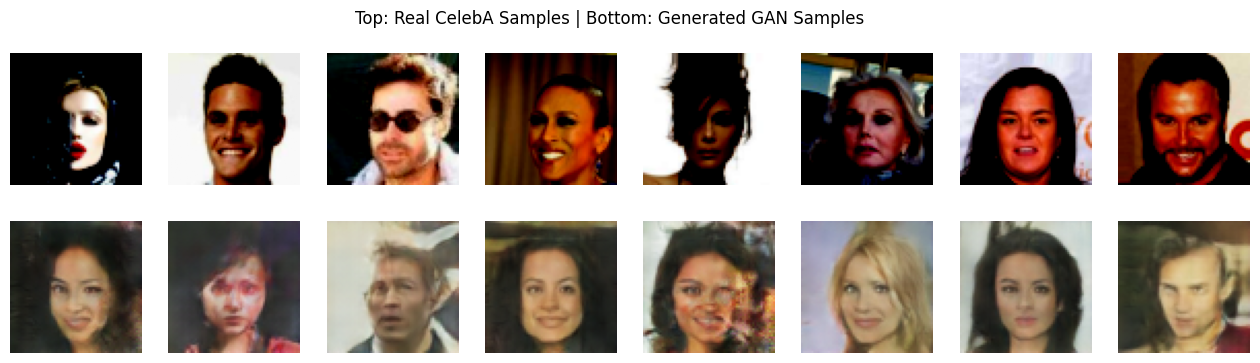

In [ ]:
#Qualitative Evaluation

import matplotlib.pyplot as plt
import numpy as np
import torchvision.transforms as transforms

# Load some real images from dataset
real_batch = next(iter(train_loader))
real_images = real_batch[0][:64]

# Generate fake images
z = torch.randn(64, z_dim, 1, 1, device=device)
fake_images = G(z).detach().cpu()
fake_images = (fake_images + 1) / 2  # scale back to [0,1]

# Plot side-by-side
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(np.transpose(real_images[i], (1, 2, 0)))
    axes[0, i].axis("off")
    axes[1, i].imshow(np.transpose(fake_images[i], (1, 2, 0)))
    axes[1, i].axis("off")

plt.suptitle("Top: Real CelebA Samples | Bottom: Generated GAN Samples", fontsize=12)
plt.show()


In [ ]:
#Quantitative – FID Score

!pip install pytorch-fid

from pytorch_fid import fid_score

real_path = "/content/real_samples"
fake_path = "/content/fake_samples"

# Save a few samples to folders
os.makedirs(real_path, exist_ok=True)
os.makedirs(fake_path, exist_ok=True)

# Save 500 real and fake images
for i in range(500):
    save_image(real_images[i % len(real_images)], os.path.join(real_path, f"{i}.png"))
    save_image(fake_images[i % len(fake_images)], os.path.join(fake_path, f"{i}.png"))

fid = fid_score.calculate_fid_given_paths([real_path, fake_path],
                                          batch_size=50,
                                          device=device,
                                          dims=2048)
print(f"FID Score: {fid:.2f}")


Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 239MB/s]
100%|██████████| 10/10 [00:02<00:00,  4.81it/s]


FID Score: 127.52


In [ ]:
# Step 6: Save trained models in Colab memory

# Create a folder to store models
os.makedirs("saved_models", exist_ok=True)

# Save the Generator and Discriminator
torch.save(G.state_dict(), "saved_models/generator.pth")
torch.save(D.state_dict(), "saved_models/discriminator.pth")

print("Trained models saved successfully in 'saved_models/' folder.")


Trained models saved successfully in 'saved_models/' folder.
